# 73 · Action chunking and temporal ensembling (pixel policy on TableTop)

In [1]:
import os, time, numpy as np, torch, matplotlib.pyplot as plt
from vlacourse import TableTop, evaluate
from vlacourse.torch_data import TableTopDataset
from vlacourse.chunk_policies import ChunkRegression, train_policy, ChunkPolicy

from vlacourse import scene_dataset
SCENE = "single"                    # TableTop scene tier (see vlacourse.SCENES)
DATA = scene_dataset(SCENE)          # 500 demos, recorded once with all CPU cores if missing
device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cuda":
    torch.cuda.set_per_process_memory_fraction(0.8)
os.makedirs("checkpoints", exist_ok=True)

def get(H, epochs=50):
    path = f"checkpoints/chunkreg_H{H}.pt"
    ds = TableTopDataset(DATA, episodes=range(450), horizon=H)
    net = ChunkRegression(horizon=H)
    if os.path.exists(path):
        net.load_state_dict(torch.load(path, map_location=device)); net.to(device)
    else:
        t0 = time.time(); train_policy(net, ds, epochs=epochs, device=device); torch.save(net.state_dict(), path)
        print(f"trained H={H} in {time.time() - t0:.0f}s")
    return net, ds

In [2]:
env = TableTop(scene=SCENE, cameras=("front", "wrist"), image_size=(128, 128), seed=0)
net1, ds1 = get(1)
net16, ds16 = get(16)
modes = {"H=1 (single step)": ChunkPolicy(net1, ds1, env, device, execute=1),
         "H=16, execute 16 (open loop)": ChunkPolicy(net16, ds16, env, device, execute=16),
         "H=16, execute 8": ChunkPolicy(net16, ds16, env, device, execute=8),
         "H=16, execute 1": ChunkPolicy(net16, ds16, env, device, execute=1),
         "H=16, temporal ensembling": ChunkPolicy(net16, ds16, env, device, ensemble=True)}
res = {}
for name, pol in modes.items():
    t0 = time.time(); res[name] = evaluate(env, pol, n_episodes=50, seed=50_000)
    print(f"{name:30s} success {res[name]['success']:.2f}  CI [{res[name]['ci'][0]:.2f}, {res[name]['ci'][1]:.2f}]  per task {res[name]['per_task']}  ({time.time() - t0:.0f}s)")

trained H=1 in 442s


H=1 (single step)              success 0.14  CI [0.07, 0.26]  per task {'pick': 0.28, 'place': 0.0}  (99s)


H=16, execute 16 (open loop)   success 0.98  CI [0.90, 1.00]  per task {'pick': 0.96, 'place': 1.0}  (7s)


H=16, execute 8                success 1.00  CI [0.93, 1.00]  per task {'pick': 1.0, 'place': 1.0}  (7s)


H=16, execute 1                success 0.28  CI [0.17, 0.42]  per task {'pick': 0.56, 'place': 0.0}  (175s)


H=16, temporal ensembling      success 1.00  CI [0.93, 1.00]  per task {'pick': 1.0, 'place': 1.0}  (70s)


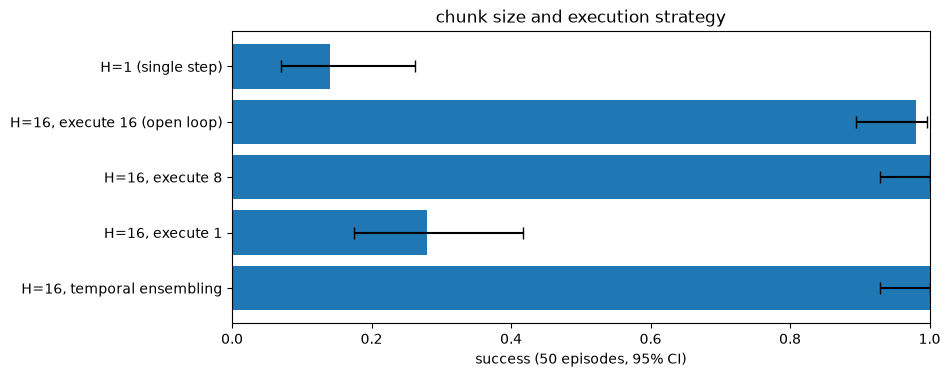

In [3]:
names = list(res); s = np.array([res[n]["success"] for n in names])
lo = np.array([res[n]["ci"][0] for n in names]); hi = np.array([res[n]["ci"][1] for n in names])
plt.figure(figsize=(9, 3.8)); plt.barh(names, s, xerr=[s - lo, hi - s], capsize=4); plt.xlim(0, 1); plt.gca().invert_yaxis()
plt.xlabel("success (50 episodes, 95% CI)"); plt.title("chunk size and execution strategy"); plt.show()

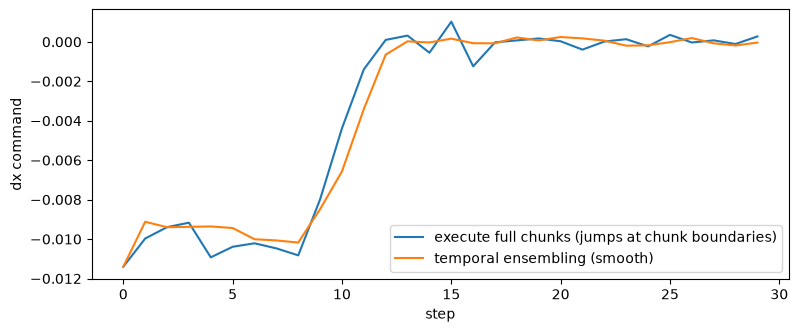

In [4]:
ep = load = None
env.reset(seed=50_003)
pol = modes["H=16, temporal ensembling"]; pol.reset(); obs = env.observe(); acts_ens = []
for _ in range(30):
    a = pol.act(obs); acts_ens.append(a); obs, *_ = env.step(a)
env.reset(seed=50_003)
pol = modes["H=16, execute 16 (open loop)"]; pol.reset(); obs = env.observe(); acts_open = []
for _ in range(30):
    a = pol.act(obs); acts_open.append(a); obs, *_ = env.step(a)
plt.figure(figsize=(9, 3.5)); plt.plot(np.array(acts_open)[:, 0], label="execute full chunks (jumps at chunk boundaries)"); plt.plot(np.array(acts_ens)[:, 0], label="temporal ensembling (smooth)")
plt.xlabel("step"); plt.ylabel("dx command"); plt.legend(); plt.show()

### Watch it: single-step vs chunked
The same episode, two policies trained on the same data. Look at the motion, not just the outcome.

In [5]:
from vlacourse import showcase as sc
a, b = "H=16, temporal ensembling", "H=1 (single step)"
sc.compare(env, {"chunk of 16 + temporal ensembling": modes[a], "single step (H=1)": modes[b]}, seed=sc.pick_seed(res[a], res[b], 50_000), title="73 chunked vs single-step")

73 chunked vs single-step: chunk of 16 + temporal ensembling: success | single step (H=1): failed


[True, False]